In [1]:
import pandas as pd
import matplotlib.pyplot as plt
print("Notebook ready!")

Notebook ready!


In [2]:
import sys
assert sys.version_info >= (3,10)

In [3]:
from packaging.version import Version
import sklearn
assert Version(sklearn.__version__) >= Version("1.6.1")

In [4]:
from pathlib import Path
import pandas as pd
import tarfile
import urllib.request

def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents=True, exist_ok=True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path="datasets", filter="data")
    return pd.read_csv(Path("datasets/housing/housing.csv"))

housing_full = load_housing_data()

It checks whether the housing dataset already exists; if not, it creates the datasets folder and downloads housing.tgz from GitHub.
It then extracts the archive into the datasets directory.
Finally, it reads housing.csv using pandas and returns it as a DataFrame.

In [5]:
housing_full.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [6]:
housing_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
housing_full["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [8]:
housing_full.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


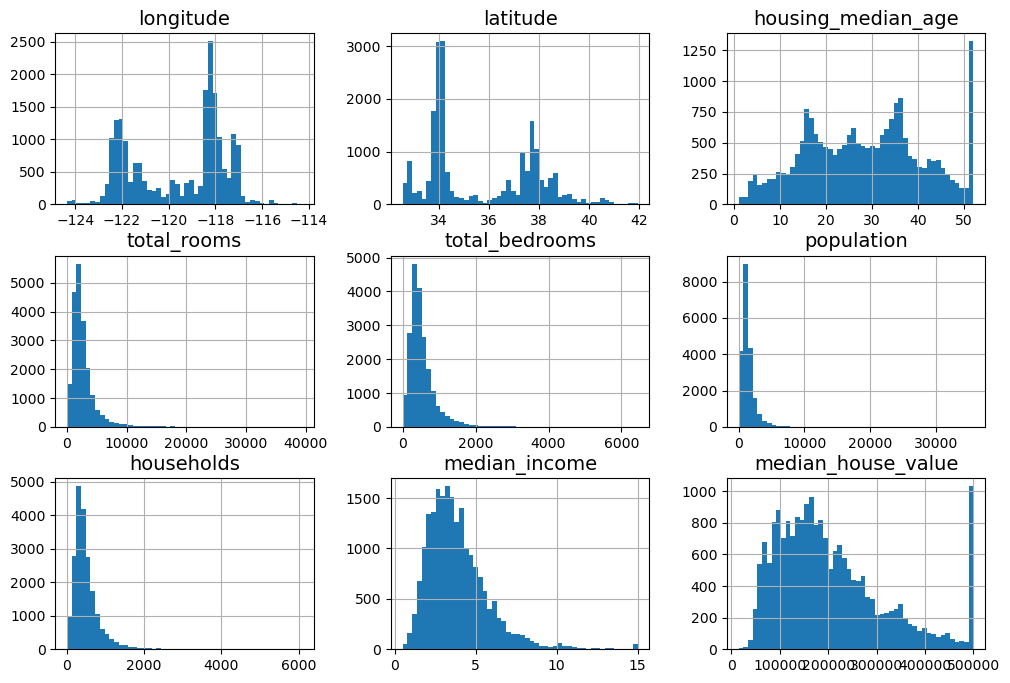

In [9]:
import matplotlib.pyplot as plt
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)
housing_full.hist(bins=50, figsize=(12,8))
plt.show()

This visually shows the distributions of the numerical features in housing_full using histograms.

In [10]:
import numpy as np
def shuffle_and_split_data(data,test_ratio,rng):
    shuffled_indices = rng.permutation(len(data))
    test_set_size = int(len(data)*test_ratio)
    test_indices = shuffled_indices[:test_set_size]
    train_indices = shuffled_indices[test_set_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

Now we will set the random seed to ensure that the notebook's outputs remain the same everytime we run it.

In [11]:
rng = np.random.default_rng(seed=42)
train_set, test_set = shuffle_and_split_data(housing_full, 0.2, rng)

Shuffled indices are just the row numbers of our dataset, put into a random order. We use them to create the training and test datasets because we want the training and test sets to be random samples of the whole dataset, and not be biased.

In [12]:
len(train_set), len(test_set)

(16512, 4128)

In [13]:
from zlib import crc32
def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32
def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]

- `crc32` → creates a hash from each ID.
- `is_id_in_test_set()` → checks whether an ID's hash falls within the `test_ratio` threshold.
- `split_data_with_id_hash()` → applies that check to every ID and returns:
  - rows **not** selected → training set
  - rows **selected** → test set

Each row has an ID, and we hash that ID to deterministically decide whether that row belongs in the **test set** based on `test_ratio`.

In [14]:
housing_with_id = housing_full.reset_index()  # adds an `index` column
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")

In [15]:
housing_with_id["id"] = (housing_full["longitude"] * 1000
                         + housing_full["latitude"])
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")

This creates a unique ID for each row using its geographic (latitudes & longitudes) coordinates. Then we use that ID's hash to put 20% of the rows into the test set and the remaining 80% into the training set.

In [16]:
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(housing_full, test_size=0.2, random_state=42)

train_test_split does the same function we did above using shuffle_and_split_data. It is just Scikit-Learn's inbuilt function.

In [17]:
test_set["total_bedrooms"].isnull().sum()

np.int64(44)

NOW WE ARE GOING TO SEE HOW TO COMPUTE PROBABILITY OF GETTING A BAD SAMPLE.
eg: A random sample of 1,000 people contains less than 49% female or more than 54% female when the population's female ratio is 51.6%.

NOTE: cdf() method of binom gives us the probability that the number of females will be equal or less than the given value.

In [18]:
from scipy.stats import binom
sample_size = 1000
ratio_female = 0.516
prob_too_small = binom(sample_size, ratio_female).cdf(490-1)
prob_too_large = 1 - binom(sample_size, ratio_female).cdf(540)
print(prob_too_small + prob_too_large)

0.10727422667455615


Confirming the above result using Simulation:

In [19]:
rng = np.random.default_rng(seed=42)
samples = (rng.random((100000,sample_size))<ratio_female).sum(axis=1)
((samples<490) | (samples>540)).mean()

np.float64(0.1077)

In [20]:
housing_full["income_cat"] = pd.cut(housing_full["median_income"],
                                    bins=[0., 1.5, 3.0, 4.5, 6., np.inf],
                                    labels=[1, 2, 3, 4, 5])

This creates income categories like label 1(0-1.5), label 2(1.5-3),..., label5(>6).

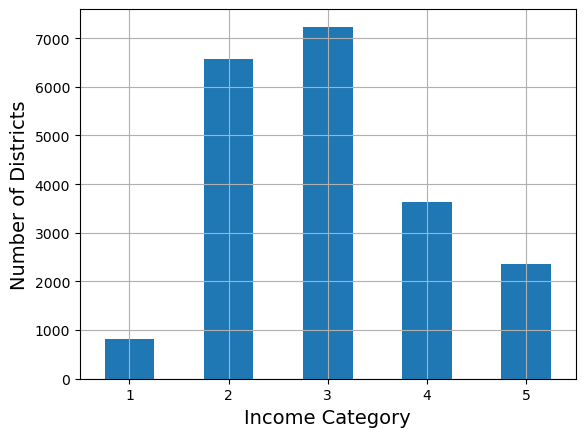

In [21]:
cat_counts = housing_full["income_cat"].value_counts().sort_index()
cat_counts.plot.bar(rot=0,grid=True)
plt.xlabel("Income Category")
plt.ylabel("Number of Districts")
plt.show()

In [22]:
from sklearn.model_selection import StratifiedShuffleSplit
splitter = StratifiedShuffleSplit(n_splits=10, test_size=0.2, random_state=42)
strat_splits = []
for train_index, test_index in splitter.split(housing_full, housing_full["income_cat"]):
    strat_train_set_n = housing_full.iloc[train_index]
    strat_test_set_n = housing_full.iloc[test_index]
    strat_splits.append((strat_train_set_n, strat_test_set_n))

It creates **10 different stratified train/test splits**.

- `StratifiedShuffleSplit` → splits randomly while keeping the **same `income_cat` proportions** in train and test.
- `n_splits=10` → creates **10 different splits**.
- `test_size=0.2` → 20% test, 80% train.
- The `for` loop gets the row indices for each split and uses `.iloc[]` to create the actual train/test DataFrames.
- `strat_splits` stores all 10 pairs of train/test sets.

In [23]:
strat_train_set, strat_test_set = strat_splits[0]

For a single stratified split, just do this:

In [24]:
strat_train_set, strat_test_set = train_test_split(
    housing_full,
    test_size=0.2,
    stratify=housing_full["income_cat"],
    random_state=42)

In [25]:
strat_test_set["income_cat"].value_counts() / len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [26]:
def income_cat_proportions(data):
    return data["income_cat"].value_counts() / len(data)
train_test, test_set = train_test_split(housing_full,test_size=0.2,random_state=42)
compare_props = pd.DataFrame({
    "Original": income_cat_proportions(housing_full),
    "Stratified": income_cat_proportions(strat_test_set),
    "Random": income_cat_proportions(test_set)
}).sort_index()
compare_props.index.name = "Income Category"
compare_props["Strat_error"] = compare_props["Stratified"]/compare_props["Original"] - 1
compare_props["Random_error"] = compare_props["Random"]/compare_props["Original"] - 1
(compare_props * 100).round(2)

,Original,Stratified,Random,Strat_error,Random_error
Income Category,,,,,
1,3.98,4.00,4.24,0.36,6.45
2,31.88,31.88,30.74,-0.02,-3.59
3,35.06,35.05,34.52,-0.01,-1.53
4,17.63,17.64,18.41,0.03,4.42
5,11.44,11.43,12.09,-0.08,5.63


It creates a table comparing **income category proportions** in:

- **Overall dataset**
- **Stratified test set**
- **Random test set**

Then it calculates the **percentage error** of the stratified and random splits compared with the overall dataset.

**Purpose:** to show that **stratified sampling preserves the income-category proportions much better than random sampling**.

In [27]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis=1, inplace=True)

This code removes the temporary income_cat column from both our training set and test set once we are done using it. inplace=true means modifying the existing dataframe instead of creating a new copy.

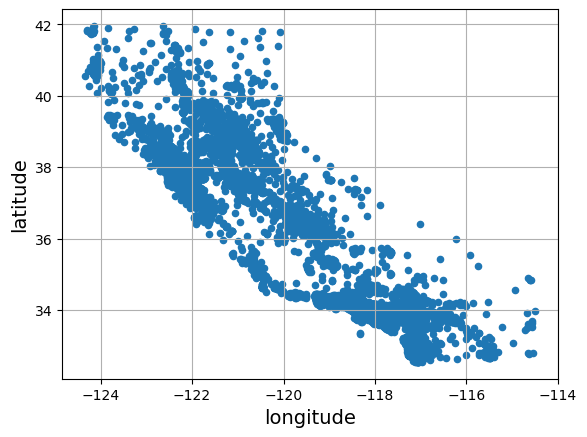

In [28]:
housing = strat_train_set.copy()
housing.plot(kind="scatter",x="longitude",y="latitude",grid=True)
plt.show()

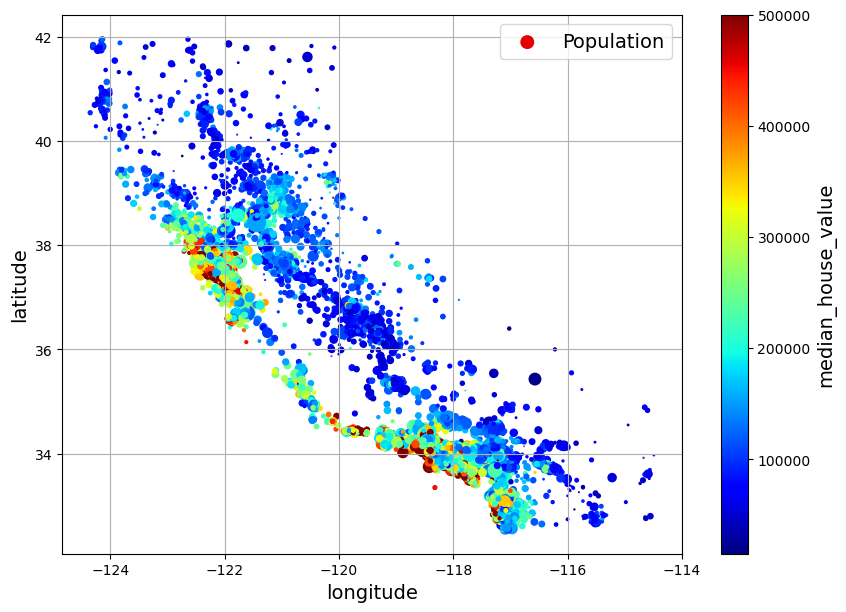

In [29]:
housing.plot(kind="scatter",x="longitude",y="latitude",grid=True,
    s=housing["population"]/100, label="Population",
    c="median_house_value", cmap="jet", colorbar=True,
    legend=True, sharex=False, figsize=(10,7))
plt.show()

HERE, s = size of each point bubble
c = color of each point
cmap = colormap("jet" means blue to red)
sharex = False as no subplots are used(sharex = sharing x-axis)

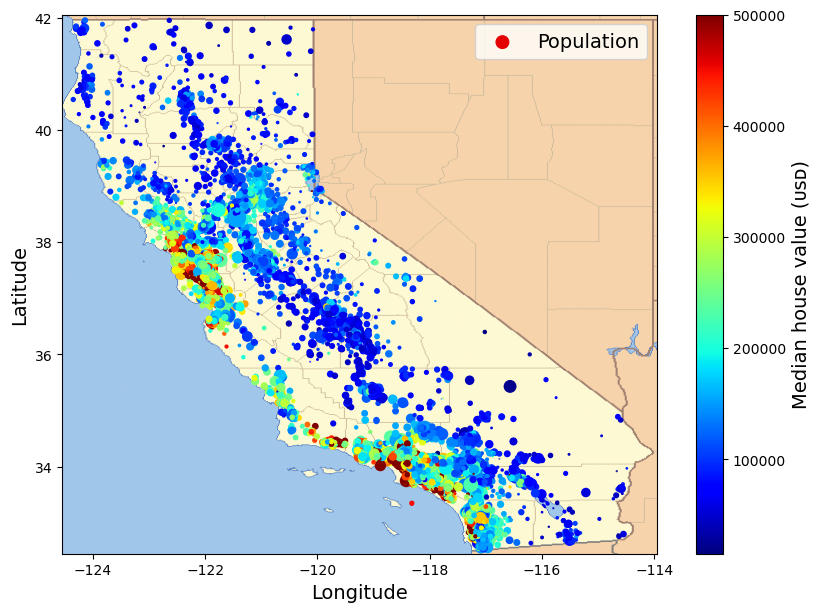

In [30]:
filename = "california.png"
filepath = Path(f"my_{filename}")
if not filepath.is_file():
    homlp_root = "https://github.com/ageron/handson-mlp/raw/main/"
    url = homlp_root + "images/end_to_end_project/" + filename
    print("Downloading", filename)
    urllib.request.urlretrieve(url, filepath)

housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed.plot(
             kind="scatter", x="Longitude", y="Latitude",
             s=housing_renamed["Population"] / 100, label="Population",
             c="Median house value (ᴜsᴅ)", cmap="jet", colorbar=True,
             legend=True, sharex=False, figsize=(10, 7))
california_img = plt.imread(filepath)
axis = -124.55, -113.95, 32.45, 42.05
plt.axis(axis)
plt.imshow(california_img, extent=axis)
plt.show()

In [31]:
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

It calculates the correlation of every numerical column with median_house_value and then sorts them from highest to lowest correlation.

housing.corr() → calculates the correlation between every pair of numerical columns, corr_matrix["median_house_value"] → selects the correlation of every numerical feature with median_house_value

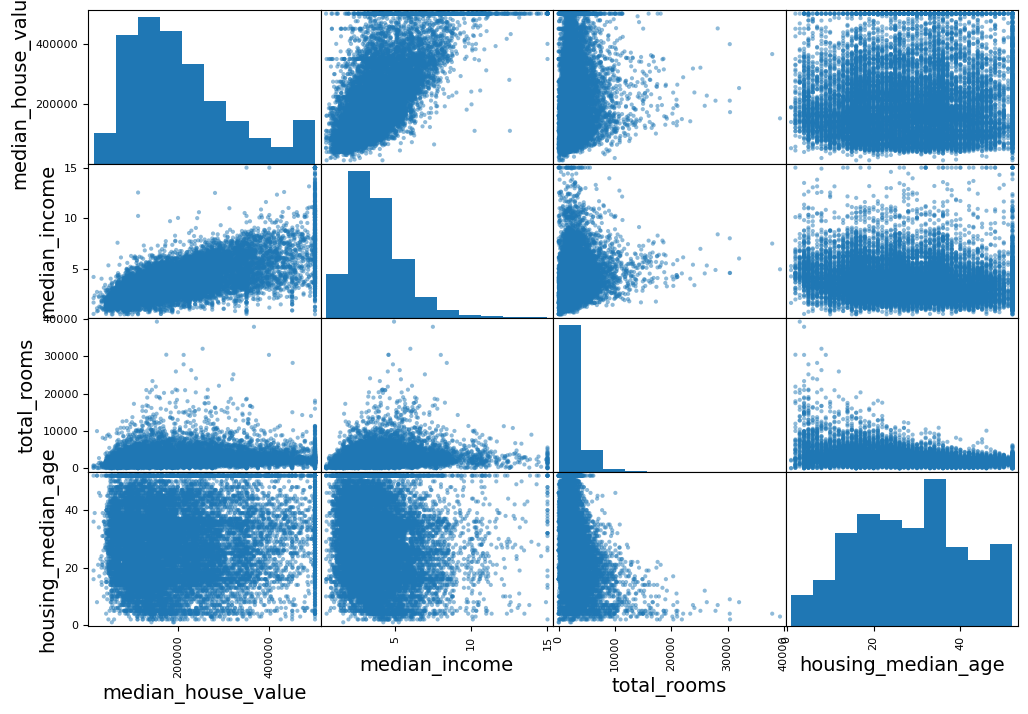

In [32]:
from pandas.plotting import scatter_matrix
attributes = ["median_house_value","median_income","total_rooms","housing_median_age"]
scatter_matrix(housing[attributes],figsize=(12,8))
plt.show()

Scatter matrix means multiple scatter plots in a figure. We compare data of 4 columns, hence figure has 16 plots. The diagonal plots are always histograms because same column vs same column has a meaningless scatter. This scatter matrix shows the plots for pairwise relationships of the 4 columns over here.

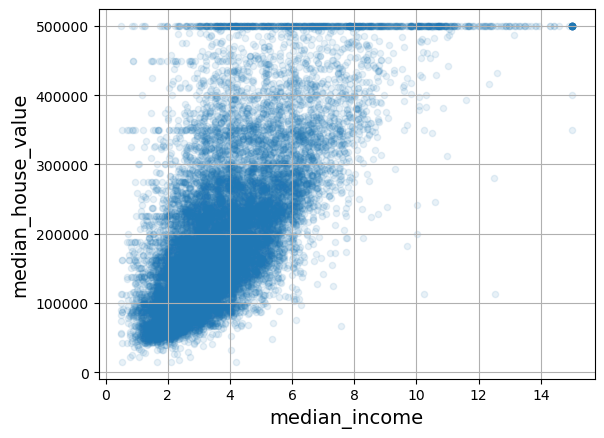

In [33]:
housing.plot(kind="scatter",x="median_income",y="median_house_value",alpha=0.1,grid=True)
plt.show()

In [34]:
housing["rooms_per_house"] = housing["total_rooms"]/housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"]/housing["total_rooms"]
housing["people_per_house"] = housing["population"]/housing["households"]
corr_matrix = housing.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688380
rooms_per_house       0.143663
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
people_per_house     -0.038224
longitude            -0.050859
latitude             -0.139584
bedrooms_ratio       -0.256397
Name: median_house_value, dtype: float64

In [35]:
housing = strat_train_set.drop("median_house_value",axis=1)
housing_labels = strat_train_set["median_house_value"].copy()

This cell resets the housing dataframe, also removing the custom features we just added.

In [36]:
null_rows_idx = housing.isnull().any(axis=1)
housing.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,NaN,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,NaN,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,NaN,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,NaN,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,NaN,375.0,183.0,9.8020,<1H OCEAN


In [37]:
housing_option1 = housing.copy()
housing_option1.dropna(subset=["total_bedrooms"], inplace=True)  # option 1
housing_option1.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity


Removing the NaN rows from the dataset.

In [38]:
housing_option2 = housing.copy()
housing_option2.drop("total_bedrooms", axis=1, inplace=True)  # option 2
housing_option2.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,375.0,183.0,9.8020,<1H OCEAN


Removing the total bedrooms column.

In [39]:
housing_option3 = housing.copy()
median = housing_option3["total_bedrooms"].median()
housing_option3["total_bedrooms"] = housing_option3["total_bedrooms"].fillna(median)
housing_option3.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962,INLAND
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115,<1H OCEAN
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917,<1H OCEAN
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033,<1H OCEAN
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020,<1H OCEAN


Filling the NaN rows with the median of the entire total bedrooms column.

In [40]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
housing_num = housing.select_dtypes(include=[np.number])
imputer.fit(housing_num)

SimpleImputer(strategy='median')

- `SimpleImputer(strategy="median")` → creates an imputer that will replace missing values with the **median**.
- `select_dtypes(...)` → selects only the **numerical columns** from `housing`.
- `imputer.fit(housing_num)` → calculates the **median of each numerical column**.

In [41]:
imputer.statistics_

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

Which is same as:

In [42]:
housing_num.median().values

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [43]:
X = imputer.transform(housing_num)
imputer.feature_names_in_

array(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype=object)

In [44]:
housing_tr = pd.DataFrame(X,columns=housing_num.columns,index=housing_num.index)
housing_tr.loc[null_rows_idx].head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
14452,-120.67,40.50,15.0,5343.0,434.0,2503.0,902.0,3.5962
18217,-117.96,34.03,35.0,2093.0,434.0,1755.0,403.0,3.4115
11889,-118.05,34.04,33.0,1348.0,434.0,1098.0,257.0,4.2917
20325,-118.88,34.17,15.0,4260.0,434.0,1701.0,669.0,5.1033
14360,-117.87,33.62,8.0,1266.0,434.0,375.0,183.0,9.8020


In [45]:
from sklearn.ensemble import IsolationForest
isolation_forest = IsolationForest(random_state=42)
outlier_pred = isolation_forest.fit_predict(X)

In [46]:
outlier_pred

array([-1,  1,  1, ...,  1,  1,  1])

If we want to drop the outliers, we would run this code:

In [47]:
#housing = housing.iloc[outlier_pred==1]
#housing_labels = housing_labels.iloc[outlier_pred==1]

In [48]:
housing_cat = housing[["ocean_proximity"]]
housing_cat.head(8)

,ocean_proximity
13096,NEAR BAY
14973,<1H OCEAN
3785,INLAND
14689,INLAND
20507,NEAR OCEAN
1286,INLAND
18078,<1H OCEAN
4396,NEAR BAY


Index 13096 is appearing first because housing is not in its row order anymore, it was created from the stratified training set, whose rows were selected using shuffled indices.

In [49]:
from sklearn.preprocessing import OrdinalEncoder
ordinal_encoder = OrdinalEncoder()
housing_cat_encoded = ordinal_encoder.fit_transform(housing_cat)
housing_cat_encoded[:8]

array([[3.],
       [0.],
       [1.],
       [1.],
       [4.],
       [1.],
       [0.],
       [3.]])

In [50]:
ordinal_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [51]:
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)

- `OneHotEncoder()` → creates an encoder that converts categories into separate binary columns.
- `fit_transform(housing_cat)` → learns the categories and converts them into a one-hot encoded sparse matrix.

Example: `INLAND` → `[1, 0, 0, 0, 0]`, `NEAR BAY` → `[0, 1, 0, 0, 0]`.

Unlike `OrdinalEncoder`, it doesn't assign categories numbers that might imply an order.

Basically jis bhi category ka row h usi ke column mei 1 hoga baaki saare columns ke liye zero hoga. ML algorithms don't understand text categories, they need numerical input. One-hot encoding converts categories into numbers without implying as false ranking. Example: INLAND = 0, NEAR BAY = 1, NEAR OCEAN = 2 use karne se algorithm galti se NEAR OCEAN > NEAR BAY > INLAND jaisa order infer kar sakta hai. One-hot encoding mein har category ka separate column hota hai, so aisa artificial order nahi banta. Sparse matrix bas is representation ko memory-efficient banati hai, kyunki mostly values 0 hota hain.

In [52]:
housing_cat_1hot

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16512 stored elements and shape (16512, 5)>

16,512 housing records ko 5 categorical columns mein encode kiya gaya hai, aur har record ki category wale column mein 1 hai. 16,512 records because training set is 80% of the dataset.

In [53]:
housing_cat_1hot.toarray()

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

By default, the OneHotEncoder class returns a sparse array, but we can convert it to a dense array if needed by calling the toarray() method. Aternatively, we can also set sparse_output = False when creating the OneHotEncoder.

In [54]:
cat_encoder = OneHotEncoder(sparse_output = False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

In [55]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

.get_dummies() is just the Pandas equivalent of sklearn.OneHotEncoder.

In [56]:
df_test = pd.DataFrame({"ocean_proximity": ["INLAND", "NEAR BAY"]})
pd.get_dummies(df_test)

,ocean_proximity_INLAND,ocean_proximity_NEAR BAY
0,True,False
1,False,True


In [57]:
cat_encoder.transform(df_test)

array([[0., 1., 0., 0., 0.],
       [0., 0., 0., 1., 0.]])

In [58]:
df_test_unknown = pd.DataFrame({"ocean_proximity":["<2H OCEAN","ISLAND"]})
pd.get_dummies(df_test_unknown)

,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


In [59]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [60]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [61]:
cat_encoder.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [62]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

In [63]:
df_output = pd.DataFrame(cat_encoder.transform(df_test_unknown),
                         columns = cat_encoder.get_feature_names_out(),
                         index = df_test_unknown.index)
df_output

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


<2H OCEAN unknown hai, isliye uski row all zeros hai. ISLAND encoder ki known categories mein hai, isliye uske column mein 1 aata hai.

In [64]:
from sklearn.preprocessing import MinMaxScaler
min_max_scaler = MinMaxScaler(feature_range=(-1,1))
housing_num_min_max_scaled = min_max_scaler.fit_transform(housing_num)

This was scaling numerical features to fit them in the range of (-1,1)

In [65]:
from sklearn.preprocessing import StandardScaler
std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)

This was transforming features such that they get standardised(mean=0,std=1).
We use fit_transform on both the methods because we first learn the scaling parameters from the data(fit), then we transform the values(transform). But when we do it on test data, we should only use .transform(), not .fit_transform()

<Axes: >

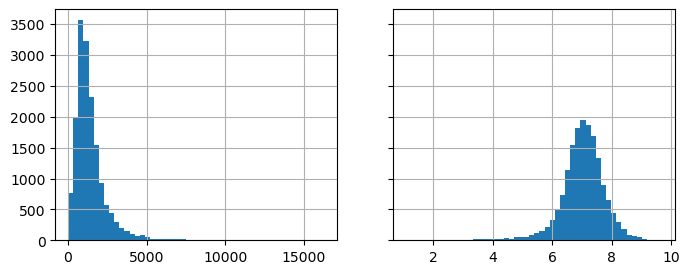

In [66]:
fig, axs = plt.subplots(1,2,figsize=(8,3),sharey=True)
housing["population"].hist(ax=axs[0],bins=50)
housing["population"].apply(np.log).hist(ax=axs[1],bins=50)

Applies the natural logarithm (np.log) to each population value, then plots the transformed values in the second histogram.
Why do this? The original population data is heavily skewed. Taking the log makes its distribution more balanced and easier for some ML algorithms to work with.

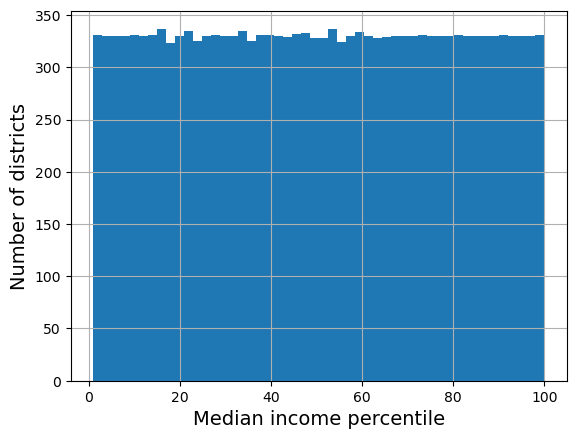

In [67]:
percentiles = [np.percentile(housing["median_income"],p) for p in range(1,100)]
flattened_median_income = pd.cut(housing["median_income"], bins = [-np.inf]+percentiles+[np.inf], labels = range(1,100+1))
flattened_median_income.hist(bins=50)
plt.xlabel("Median income percentile")
plt.ylabel("Number of districts")
plt.show()
# Note: incomes below the 1st percentile are labeled 1, and incomes above the
# 99th percentile are labeled 100. This is why the distribution below ranges
# from 1 to 100 (not 0 to 100).

This code replaces each median_income value with its percentile rank (1–100) to make the distribution more uniform.
- np.percentile(...) → calculates the income values at each percentile, from 1st to 99th.
- pd.cut(...) → places each income value into a percentile range and labels it from 1 to 100.
- [-np.inf] → includes values smaller than the first percentile.
- [np.inf] → includes values greater than the 99th percentile.

The transformed data is evenly distributed, but the original data is still skewed.
Many districts may have low incomes and only a few high incomes. Percentile transformation changes their values to ranks from 1–100, making the distribution more uniform. It doesn't change the actual number of low-income or high-income districts. Each median-income percentile interval contains roughly the same number of districts, which is why the bars have almost equal heights.


Q. How does percentile ranking convert skewed original data into a uniform distribution?

Ans.  Because percentiles spread data points evenly across percentage slices (e.g., 1% of the data falls between the 0th and 1st percentile, 1% between the 1st and 2nd, and so on), the dense clusters and sparse tails of a skewed distribution are stretched or compressed into equal-sized frequency bins.

In [68]:
from sklearn.metrics.pairwise import rbf_kernel
age_similarity_35 = rbf_kernel(housing[["housing_median_age"]],[[35]],gamma=0.1)

This calculates how similar each district’s median housing age is to 35 years.
- gamma=0.1 → controls how quickly similarity decreases with age difference.
- rbf_kernel(...) → returns a similarity score for each district, between 0 and 1.

The RBF (Radial Basis Function) kernel helps an ML model learn non-linear relationships. The RBF kernel measures how similar two data points are based on their distance:
- Close points → similarity near 1
- Far-apart points → similarity near 0

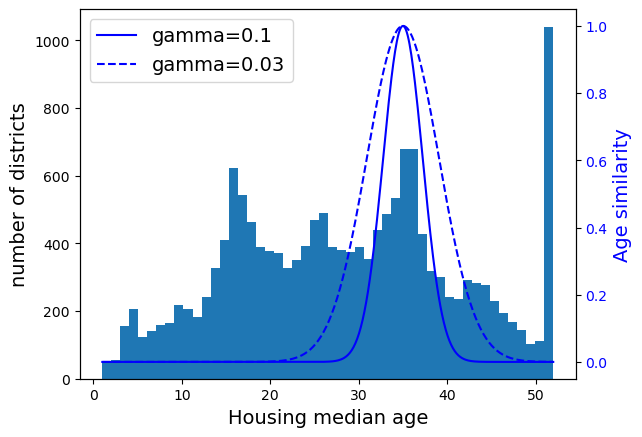

In [69]:
ages = np.linspace(housing["housing_median_age"].min(),housing["housing_median_age"].max(),500).reshape(-1,1)
gamma1 = 0.1
gamma2 = 0.03
rbf1 = rbf_kernel(ages,[[35]],gamma=gamma1)
rbf2 = rbf_kernel(ages,[[35]],gamma=gamma2)

fig, ax1 = plt.subplots()
ax1.set_xlabel("Housing median age")
ax1.set_ylabel("number of districts")
ax1.hist(housing["housing_median_age"],bins=50)

ax2 = ax1.twinx() # creates a twin axis sharing the same x_axis
color = "blue"
ax2.plot(ages,rbf1,color=color,label="gamma=0.1")
ax2.plot(ages,rbf2,color=color,label="gamma=0.03",linestyle="--")
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylabel("Age similarity", color=color)
plt.legend(loc="upper left")
plt.show()

This graph shows two things:

- Blue bars: How many districts have each housing median age.
- Blue curves: How similar each age is to 35 years, using two different `gamma` values.

Solid curve (`gamma = 0.1`): Similarity drops quickly as age moves away from 35.

Dashed curve (`gamma = 0.03`): Similarity drops more slowly, so a wider range of ages is considered similar to 35.

Both curves reach their maximum similarity of 1 at age 35.

Main takeaway: Higher `gamma` means a narrower similarity range; lower `gamma` means a wider range.

In this code, the goal is to create a new feature from housing_median_age. Instead of directly using the age, we calculate how similar each district's age is to a chosen reference age. This similarity score becomes a new numerical feature the ML model can use. This is feature scaling. 35 is an example reference point; it is not automatically the best age or the average age. We could choose another reference age, such as 20 or 40, to create a different feature.

In [70]:
from sklearn.linear_model import LinearRegression
target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())
# .to_frame() is needed because StandardScaler expects a 2D array, but housing_labels is a Series (1D array)
model = LinearRegression()
model.fit(housing[["median_income"]], scaled_labels)
some_new_data = housing[["median_income"]].iloc[:5]  # pretend this is new data
scaled_predictions = model.predict(some_new_data)
predictions = target_scaler.inverse_transform(scaled_predictions)
predictions

array([[131997.15275877],
       [299359.35844434],
       [146023.37185694],
       [138840.33653057],
       [192016.61557639]])

- fit_transform(...) — scales the house values to have approximately mean 0 and standard deviation 1.
- model.fit(...) — trains the model using median_income as input and the scaled house values as targets.
- inverse_transform(...) — converts the predictions back to the original house-value scale (USD).

In [71]:
from sklearn.compose import TransformedTargetRegressor
model = TransformedTargetRegressor(LinearRegression(),transformer=StandardScaler())
model.fit(housing[["median_income"]],housing_labels)
predictions = model.predict(some_new_data)
predictions

array([131997.15275877, 299359.35844434, 146023.37185694, 138840.33653057,
       192016.61557639])

TransformedTargetRegressor automatically scales the target values during training and reverses the scaling during prediction. This saves us from manually calling fit_transform() and inverse_transform().

In [72]:
from sklearn.preprocessing import FunctionTransformer
log_transformer = FunctionTransformer(np.log, inverse_func=np.exp)
log_pop = log_transformer.transform(housing[["population"]])

We use FunctionTransformer to turn existing Python functions into Scikit-Learn transformers.
Here, our purpose is to create a transformed population feature with less skew.


In [73]:
rbf_transformer = FunctionTransformer(rbf_kernel,kw_args=dict(Y=[[35]], gamma=0.1))
age_simil_35 = rbf_transformer.transform(housing[["housing_median_age"]])

- rbf_kernel is the function being wrapped.
- Y=[[35]] sets the reference age to 35.
- gamma=0.1 controls how quickly similarity decreases with distance from 35.
- .transform(...) calculates each district's age similarity to 35.
The output age_simil_35 will contain the similarity score wrt 35 for each district.

In [74]:
sf_coords = 37.7749, -122.41
sf_transformer = FunctionTransformer(rbf_kernel,kw_args=dict(Y=[sf_coords], gamma=0.1))
sf_simil = sf_transformer.transform(housing[["latitude", "longitude"]])
sf_simil

array([[0.999927  ],
       [0.05258419],
       [0.94864161],
       ...,
       [0.00388525],
       [0.05038518],
       [0.99868067]])

- sf_coords stores San Francisco's latitude and longitude.
- Y=[sf_coords] makes those coordinates the reference point.
- .transform(...) calculates how similar each district's location is to San Francisco's location.
High score (near 1) means geographically close; low score (near 0) means farther away.

In [75]:
ratio_transformer = FunctionTransformer(lambda X: X[:, [0]] / X[:, [1]])
ratio_transformer.transform(np.array([[1., 2.], [3., 4.]]))

array([[0.5 ],
       [0.75]])

This creates a transformer that divides the first column by the second column for each row.

For `[[1., 2.], [3., 4.]]`, the output is `[[0.5], [0.75]]`.

`X[:, [0]]` selects the first column; `X[:, [1]]` selects the second.

In [76]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class StandardScalerClone(BaseEstimator,TransformerMixin):
    def __init__(self,with_mean=True):
        self.with_mean = with_mean

    def fit(self,X,y=None): # y is required for compatibility with the scikit-learn API, but we don't need it here
        X = check_array(X)
        self.mean_ = X.mean(axis=0)
        self.scale_ = X.std(axis=0)
        self.scale_[self.scale_ == 0] = 1  # Avoid division by zero for constant features
        self.n_features_in_ = X.shape[1]  # every estimator stores this(the number of input columns) in fit()
        return self  # always return self!

    def transform(self,X):
        check_is_fitted(self)  # looks for learned attributes (with trailing _)
        X = check_array(X)
        assert self.n_features_in_ == X.shape[1]
        if self.with_mean:
            X = X - self.mean_
        return X / self.scale_

sklearn.base contains base classes and tools for scikit-learn's estimators. An estimator is an object which learns from data using .fit(), like transformers and models.
- BaseEstimator → gives your class standard parameter-handling features.
- TransformerMixin → provides fit_transform() based on our fit() and transform() methods.
sklearn.utils.validation contains helper functions that check whether data and estimators are valid before we use them. check_array(x) checks whether an array X is a valid numerical array, and check_is_fitted(self) checks whether an estimator has already been fitted, i.e. whether the attributes learned during .fit() exist or not. If not, it raises an error instead of running transform() incorrectly.

In the above code, basically each feature is standardized to approximately mean 0 and standard deviation 1 when with_mean=True. This is done using StandardScalerClone.

In [77]:
from sklearn.cluster import KMeans

class ClusterSimilarity(BaseEstimator, TransformerMixin):
    def __init__(self,n_clusters=10,gamma=1,random_state=None):
        self.n_clusters = n_clusters
        self.gamma = gamma
        self.random_state = random_state
    def fit(self,X,y=None,sample_weight=None):
        self.kmeans_ = KMeans(self.n_clusters,random_state=self.random_state)
        self.kmeans_.fit(X,sample_weight=sample_weight)
        return self
    def transform(self,X):
        return rbf_kernel(X,self.kmeans_.cluster_centers_,gamma=self.gamma)
    def get_feature_names_out(self,names=None):
        return [f"Cluster {i} similarity" for i in range(self.n_clusters)]

KMeans groups similar data points into clusters. The class ClusterSimilarity creates a custom transformer that works with Scikit-Learn pipelines.

__init__() :-
- n_clusters=10 → create 10 clusters.
- gamma=1 → controls how quickly similarity decreases with distance.
- random_state → controls randomness so results can be reproducible.

fit() (finds the clusters) :- 
- Creates a KMeans model.
- .fit(X) learns the cluster locations from your data.
- sample_weight optionally lets some data points count more than others.
- return self returns the fitted transformer.

transform() :- Calculates how similar each data point is to each cluster center using the RBF kernel.

get_feature_names_out() :- Names the output columns. get_feature_names_out() provides names for the new output columns, such as Cluster 0 similarity, Cluster 1 similarity, … Cluster 9 similarity.

Purpose: Help the model capture geographic patterns in the housing data.

Suppose each district has latitude and longitude. This transformer:
1. Finds 10 geographic clusters.
2. Measures each district's similarity to all 10 cluster centers.
3. Returns 10 new numerical features per district.
Why? Instead of giving the model only raw coordinates, we give it features describing how close each district is to different geographic regions.

In [78]:
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
similarities = cluster_simil.fit_transform(housing[["latitude", "longitude"]])
similarities[:3].round(2)

c:\Users\LENOVO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\LENOVO\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\LENOVO\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\LENOVO\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^

array([[0.46, 0.  , 0.08, 0.  , 0.  , 0.  , 0.  , 0.98, 0.  , 0.  ],
       [0.  , 0.96, 0.  , 0.03, 0.04, 0.  , 0.  , 0.  , 0.11, 0.35],
       [0.34, 0.  , 0.45, 0.  , 0.  , 0.  , 0.01, 0.73, 0.  , 0.  ]])

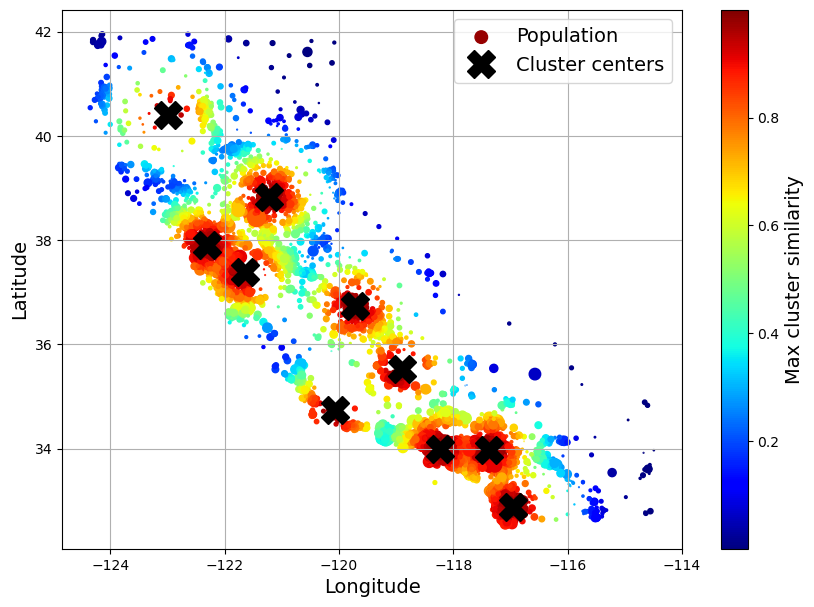

In [79]:
housing_renamed = housing.rename(columns={
    "latitude": "Latitude", "longitude": "Longitude",
    "population": "Population",
    "median_house_value": "Median house value (ᴜsᴅ)"})
housing_renamed["Max cluster similarity"] = similarities.max(axis=1)
housing_renamed.plot(kind="scatter", x="Longitude", y="Latitude", grid=True,
                     s=housing_renamed["Population"] / 100, label="Population",
                     c="Max cluster similarity",
                     cmap="jet", colorbar=True,
                     legend=True, sharex=False, figsize=(10, 7))
plt.plot(cluster_simil.kmeans_.cluster_centers_[:, 1],
         cluster_simil.kmeans_.cluster_centers_[:, 0],
         linestyle="", color="black", marker="X", markersize=20,
         label="Cluster centers")
plt.legend(loc="upper right")
plt.show()

In [80]:
from sklearn.pipeline import Pipeline
num_pipeline = Pipeline([
    ("impute",SimpleImputer(strategy="median")),
    ("standardize",StandardScaler())
])

In [81]:
from sklearn.pipeline import make_pipeline
num_pipeline = make_pipeline(SimpleImputer(strategy="median"),StandardScaler())

In [82]:
from sklearn import set_config
set_config(display='diagram')
num_pipeline

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

This pipeline automatically performs two preprocessing steps in order:

1. `SimpleImputer(strategy="median")` — fills missing numerical values with each column's median.
2. `StandardScaler()` — scales the numerical columns to mean ≈ 0 and standard deviation ≈ 1.

The second code uses `make_pipeline()` to create essentially the same pipeline, with step names generated automatically.

`set_config(display="diagram")` displays the pipeline visually.

Why useful? You can call `num_pipeline.fit_transform(housing_num)` to run both steps automatically.

In [83]:
housing_num_prepared = num_pipeline.fit_transform(housing_num)
housing_num_prepared[:2].round(2)

array([[-1.42,  1.01,  1.86,  0.31,  1.37,  0.14,  1.39, -0.94],
       [ 0.6 , -0.7 ,  0.91, -0.31, -0.44, -0.69, -0.37,  1.17]])

In [84]:
df_housing_num_prepared = pd.DataFrame(
    housing_num_prepared, columns = num_pipeline.get_feature_names_out(),
    index = housing_num.index)

In [85]:
df_housing_num_prepared.head(2)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942


In [86]:
num_pipeline.steps

[('simpleimputer', SimpleImputer(strategy='median')),
 ('standardscaler', StandardScaler())]

In [87]:
num_pipeline[1]

StandardScaler()

In [88]:
num_pipeline[:-1]

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median'))])

In [89]:
num_pipeline.named_steps["simpleimputer"]

SimpleImputer(strategy='median')

It accesses the `SimpleImputer` object inside `num_pipeline`, so you can inspect its settings or learned values, such as the medians it calculated.

In [90]:
num_pipeline.set_params(simpleimputer__strategy="median")

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler())])

In [91]:
from sklearn.compose import ColumnTransformer
num_attribs = ["longitude","latitude","housing_median_age","total_rooms",
               "total_bedrooms","population", "households", "median_income"]
cat_attribs = ["ocean_proximity"]
cat_pipeline = make_pipeline(SimpleImputer(strategy="most_frequent"),OneHotEncoder(handle_unknown="ignore"))
preprocessing = ColumnTransformer([
    ("num",num_pipeline,num_attribs),
    ("cat",cat_pipeline,cat_attribs)
])

cat_pipeline handles that categorical column in two steps:
1. SimpleImputer(strategy="most_frequent") fills missing values with the most common category.
2. OneHotEncoder(handle_unknown="ignore") converts categories into numeric indicator columns. If a new category appears later, it won’t cause an error.

ColumnTransformer applies the appropriate processing to each group:
- "num" applies num_pipeline to the numeric columns.
- "cat" applies cat_pipeline to the categorical column.

The transformed numeric and categorical features are then combined into one feature matrix, which can be used later as: `X_prepared = preprocessing.fit_transform(housing)`

In [92]:
from sklearn.compose import make_column_selector, make_column_transformer
preprocessing = make_column_transformer(
    (num_pipeline, make_column_selector(dtype_include=np.number)),
    (cat_pipeline, make_column_selector(dtype_include=object))
)

This code means: automatically select numerical columns and run num_pipeline on them; select text columns and run cat_pipeline on them.
Remember: ColumnTransformer is the class; make_column_transformer() is its convenient shortcut; make_column_selector() chooses which columns each transformer receives.

In [93]:
housing_prepared = preprocessing.fit_transform(housing)
housing_prepared_fr = pd.DataFrame(
    housing_prepared,
    columns=preprocessing.get_feature_names_out(),
    index=housing.index)
housing_prepared_fr.head(2)

,pipeline-1__longitude,pipeline-1__latitude,pipeline-1__housing_median_age,pipeline-1__total_rooms,pipeline-1__total_bedrooms,pipeline-1__population,pipeline-1__households,pipeline-1__median_income,pipeline-2__ocean_proximity_<1H OCEAN,pipeline-2__ocean_proximity_INLAND,pipeline-2__ocean_proximity_ISLAND,pipeline-2__ocean_proximity_NEAR BAY,pipeline-2__ocean_proximity_NEAR OCEAN
13096,-1.423037,1.013606,1.861119,0.311912,1.368167,0.137460,1.394812,-0.936491,0.0,0.0,0.0,1.0,0.0
14973,0.596394,-0.702103,0.907630,-0.308620,-0.435925,-0.693771,-0.373485,1.171942,1.0,0.0,0.0,0.0,0.0


In [94]:
def column_ratio(X):
    return X[:,[0]]/X[:,[1]]

def ratio_name(function_transformer,feature_names_in):
    return ["ratio"]

def ratio_pipeline():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        FunctionTransformer(column_ratio, feature_names_out=ratio_name),
        StandardScaler())

log_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    FunctionTransformer(np.log, feature_names_out="one-to-one"),
    StandardScaler())
cluster_simil = ClusterSimilarity(n_clusters=10, gamma=1., random_state=42)
default_num_pipeline = make_pipeline(SimpleImputer(strategy="median"),
                                     StandardScaler())
preprocessing = ColumnTransformer([
        ("bedrooms", ratio_pipeline(), ["total_bedrooms", "total_rooms"]),
        ("rooms_per_house", ratio_pipeline(), ["total_rooms", "households"]),
        ("people_per_house", ratio_pipeline(), ["population", "households"]),
        ("log", log_pipeline, ["total_bedrooms", "total_rooms", "population",
                               "households", "median_income"]),
        ("geo", cluster_simil, ["latitude", "longitude"]),
        ("cat", cat_pipeline, make_column_selector(dtype_include=object))],
    remainder=default_num_pipeline)  # one column remaining: housing_median_age

- column_ratio() divides the first selected column by the second. Its used for features like bedrooms_per_household.
- ratio_name() gives the resulting feature the name "ratio".
- ratio_pipeline() runs three steps: fill missing values → calculate the ratio → scale it.
- log_pipeline: For selected numerical columns, it fills missing values, applies the natural log, then scales the results.
- cluster_simil: Creates 10 geographic clusters and calculates each district's similarity to each cluster.
- default_num_pipeline: For numerical columns that don't have a special transformation, it fills missing values and scales them.
- Finally we combine all of these using ColumnTransformer.

remainder=default_num_pipeline means any columns not explicitly assigned above go through the default numerical pipeline. We are engineering more useful features from the raw data and automating all preprocessing in one reusable object.

In [95]:
housing_prepared = preprocessing.fit_transform(housing)
housing_prepared.shape

(16512, 24)

In [96]:
preprocessing.get_feature_names_out()

array(['bedrooms__ratio', 'rooms_per_house__ratio',
       'people_per_house__ratio', 'log__total_bedrooms',
       'log__total_rooms', 'log__population', 'log__households',
       'log__median_income', 'geo__Cluster 0 similarity',
       'geo__Cluster 1 similarity', 'geo__Cluster 2 similarity',
       'geo__Cluster 3 similarity', 'geo__Cluster 4 similarity',
       'geo__Cluster 5 similarity', 'geo__Cluster 6 similarity',
       'geo__Cluster 7 similarity', 'geo__Cluster 8 similarity',
       'geo__Cluster 9 similarity', 'cat__ocean_proximity_<1H OCEAN',
       'cat__ocean_proximity_INLAND', 'cat__ocean_proximity_ISLAND',
       'cat__ocean_proximity_NEAR BAY', 'cat__ocean_proximity_NEAR OCEAN',
       'remainder__housing_median_age'], dtype=object)

In [97]:
from sklearn.linear_model import LinearRegression
lin_reg = make_pipeline(preprocessing, LinearRegression())
lin_reg.fit(housing, housing_labels)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x000...
                                                   'median_income']),
                                                 ('geo',
                                                  ClusterSimilarity(gamma=1.0,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000023C00076D50>)])),
                ('linearregression', LinearRegression())])

Creates one pipeline with two steps:
1. preprocessing — cleans and transforms the raw housing data (imputation, scaling, ratios, etc.).
2. LinearRegression() — learns the relationship between the processed features and house prices.

The benefit of make_pipeline() is that we don't need to preprocess the data manually before every training or prediction.

In [98]:
housing_predictions = lin_reg.predict(housing)
housing_predictions[:5].round(-2) #-2 -> round off to the nearest hundred.

array([246000., 372700., 135700.,  91400., 330900.])

In [99]:
housing_labels.iloc[:5].values

array([458300., 483800., 101700.,  96100., 361800.])

In [100]:
error_ratios = housing_predictions[:5].round(-2)/housing_labels.iloc[:5].values - 1
print(", ".join([f"{100 * ratio:.1f}%" for ratio in error_ratios]))

-46.3%, -23.0%, 33.4%, -4.9%, -8.5%


In [101]:
from sklearn.metrics import root_mean_squared_error
lin_rmse = root_mean_squared_error(housing_labels,housing_predictions)
lin_rmse

68972.88910758472

In [102]:
from sklearn.tree import DecisionTreeRegressor
tree_reg = make_pipeline(preprocessing,DecisionTreeRegressor(random_state=42))
tree_reg.fit(housing,housing_labels);

In [103]:
housing_predictions = tree_reg.predict(housing)
tree_rmse = root_mean_squared_error(housing_labels, housing_predictions)
tree_rmse

0.0

Why is the RMSE 0.0?

A Decision Tree can memorize its training data by creating very specific rules. Here, it predicts the training examples perfectly, giving an RMSE of 0.0. This does not mean the model is perfect on new houses. Test it on data it has never seen to check how well it generalizes.

A Decision Tree memorizes training data by creating very specific rules until it can predict each training example almost perfectly.
We haven't specified a maximum depth or minimum number of samples per leaf, so the tree can grow very deep if needed.
We give it the same houses it learned from. It has already built rules around these examples, so it can reproduce their target values exactly, resulting in tree_rmse=0

In [104]:
from sklearn.model_selection import cross_val_score
tree_rmses = -cross_val_score(tree_reg,housing,housing_labels,scoring="neg_root_mean_squared_error",cv=10)

- cv=10: Splits data into 10 folds; trains 10 times, each time using 9 folds for training and 1 for validation.
- scoring="neg_root_mean_squared_error": Scikit-learn returns negative RMSE because its scoring system treats higher scores as better.
- -cross_val_score(...): Negates the results to get positive RMSE values.

In [105]:
pd.Series(tree_rmses).describe()

count       10.000000
mean     66573.734600
std       1103.402323
min      64607.896046
25%      66204.731788
50%      66388.272499
75%      66826.257468
max      68532.210664
dtype: float64

Notice how the RMSE values here are so large.
This happens because the Decision Tree is overfitting.

- Training RMSE = 0: The tree memorizes the training data.
- Cross-validation RMSE ≈ $66,574: On unseen validation data, its predictions are much less accurate.

Why? The tree learns very specific rules from its training examples. Those rules don't generalize well to new houses. Basically it overfits.

In [106]:
lin_rmses = cross_val_score(lin_reg,housing,housing_labels,scoring="neg_root_mean_squared_error",cv=10)
pd.Series(lin_rmses).describe()

count       10.000000
mean    -70003.404818
std       4182.188328
min     -81037.863741
25%     -70344.943988
50%     -68743.995249
75%     -68172.065831
max     -65504.765753
dtype: float64

Linear Model has worse CV RMSE as compared to decision tree model.

In [109]:
from sklearn.ensemble import RandomForestRegressor
forest_reg = make_pipeline(preprocessing,RandomForestRegressor(random_state=42))
forest_rmses = -cross_val_score(forest_reg,housing,housing_labels,scoring="neg_root_mean_squared_error",cv=10)

In [110]:
pd.Series(forest_rmses).describe()

count       10.000000
mean     47038.092799
std       1021.491757
min      45495.976649
25%      46510.418013
50%      47118.719249
75%      47480.519175
max      49140.832210
dtype: float64

In [111]:
forest_reg.fit(housing,housing_labels)
housing_predictions = forest_reg.predict(housing)
forest_rmse = root_mean_squared_error(housing_labels,housing_predictions)
forest_rmse

17551.2122500877

The training error is much lower than the validation error, which usually means that the model has overfit the training set. Another possible explanation may be that there's a mismatch between the training data and the validation data, but it's not the case here, since both came from the same dataset that we shuffled and split in two parts.

In [112]:
from sklearn.model_selection import GridSearchCV
full_pipeline = Pipeline([
    ("preprocessing", preprocessing),
    ("random_forest", RandomForestRegressor(random_state=42)),
])
param_grid = [
    {'preprocessing__geo__n_clusters': [5, 8, 10],
     'random_forest__max_features': [4, 6, 8]},
    {'preprocessing__geo__n_clusters': [10, 15],
     'random_forest__max_features': [6, 8, 10]},
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=3,
                           scoring='neg_root_mean_squared_error')
grid_search.fit(housing, housing_labels)

GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                     SimpleImputer(strategy='median')),
                                                                                    ('standardscaler',
                                                                                     StandardScaler())]),
                                                          transformers=[('bedrooms',
                                                                         Pipeline(steps=[('simpleimputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('functiontransformer',
                                                                                          FunctionTransformer(feature_names_out=<f...
                                                                         <sklearn.compose._column_transformer.make_column_selector object at 0x0000023C00076D50>)])),
                                       ('random_forest',
                                        RandomForestRegressor(random_state=42))]),
             param_grid=[{'preprocessing__geo__n_clusters': [5, 8, 10],
                          'random_forest__max_features': [4, 6, 8]},
                         {'preprocessing__geo__n_clusters': [10, 15],
                          'random_forest__max_features': [6, 8, 10]}],
             scoring='neg_root_mean_squared_error')

This code uses Grid Search to find the best Random Forest model settings.

#### What each part does

- `full_pipeline`: Combines preprocessing with a `RandomForestRegressor`.
- `param_grid`: Specifies settings to test:
  - `preprocessing__geo__n_clusters`: Number of geographic clusters.
  - `random_forest__max_features`: Number of features considered when splitting each tree.
- `cv=3`: Tests each configuration using 3-fold cross-validation.
- `scoring='neg_root_mean_squared_error'`: Evaluates prediction error; lower RMSE is better.
- `grid_search.fit(housing, housing_labels)`: Tries the configurations and finds the best one.

Why use `__` in parameter names? It lets you access parameters inside nested pipelines. For example, `random_forest__max_features` refers to `max_features` inside the `random_forest` pipeline step.

In short, instead of manually guessing settings, Grid Search tests combinations and selects the best-performing one using cross-validation. Grid search is a technique of fine-tuning the hyperparameters of a ML model(like tree depth, learning rate, no.of clusters). To get best settings, we use `grid_search.best_params_`. We can get the full list of hyperparameters available for tuning by looking at `full_pipeline.get_params().keys()`.

In [113]:
# extra code – shows part of the output of get_params().keys()
print(str(full_pipeline.get_params().keys())[:1000] + "...")

dict_keys(['memory', 'steps', 'transform_input', 'verbose', 'preprocessing', 'random_forest', 'preprocessing__force_int_remainder_cols', 'preprocessing__n_jobs', 'preprocessing__remainder__memory', 'preprocessing__remainder__steps', 'preprocessing__remainder__transform_input', 'preprocessing__remainder__verbose', 'preprocessing__remainder__simpleimputer', 'preprocessing__remainder__standardscaler', 'preprocessing__remainder__simpleimputer__add_indicator', 'preprocessing__remainder__simpleimputer__copy', 'preprocessing__remainder__simpleimputer__fill_value', 'preprocessing__remainder__simpleimputer__keep_empty_features', 'preprocessing__remainder__simpleimputer__missing_values', 'preprocessing__remainder__simpleimputer__strategy', 'preprocessing__remainder__standardscaler__copy', 'preprocessing__remainder__standardscaler__with_mean', 'preprocessing__remainder__standardscaler__with_std', 'preprocessing__remainder', 'preprocessing__sparse_threshold', 'preprocessing__transformer_weights', 

In [114]:
# The best hyperparameter combination found is:
grid_search.best_params_

{'preprocessing__geo__n_clusters': 15, 'random_forest__max_features': 6}

In [115]:
grid_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                              SimpleImputer(strategy='median')),
                                                             ('standardscaler',
                                                              StandardScaler())]),
                                   transformers=[('bedrooms',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('functiontransformer',
                                                                   FunctionTransformer(feature_names_out=<function ratio_name at 0x0000023...
                                                                    n_clusters=15,
                                                                    random_state=42),
                                                  ['latitude', 'longitude']),
                                                 ('cat',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x0000023C12069610>)])),
                ('random_forest',
                 RandomForestRegressor(max_features=6, random_state=42))])

`.best_estimator_` returns the **best-performing model object** along with all the optimized settings that Grid Search found.

As soon as you run `grid_search.fit()`, Grid Search tests all combinations and finds the one that gives the best score (here, the lowest RMSE). It then retrains the model on the entire dataset using those particular settings and saves it in `best_estimator_`.

The advantage of this is that you don't need to manually declare a model again and pass the best parameters separately. You can directly use `grid_search.best_estimator_` like a new model and call `predict()` on it.

In [116]:
cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
# extra code – these few lines of code just make the DataFrame look nicer
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
score_cols = ["split0", "split1", "split2", "mean_test_rmse"]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
12,15,6,42725,43708,44335,43590
13,15,8,43486,43820,44900,44069
6,10,4,43798,44036,44961,44265
9,10,6,43710,44163,44967,44280
7,10,6,43710,44163,44967,44280


This code displays the Grid Search results in a clean table, sorted by best performance.
- pd.DataFrame(grid_search.cv_results_): Converts the search results into a DataFrame.
- sort_values(...): Sorts configurations by mean_test_score, best first. Because the score is negative RMSE, higher scores mean lower RMSE.

The best configuration shown uses n_clusters = 15 and max_features = 6, with a mean validation RMSE of about 43,590. Lower RMSE is better.

In [118]:
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingRandomSearchCV

Imagine you have 16 model configurations to test.
Instead of spending equal time training all 16, halving search starts with limited resources, removes weaker configurations, and gives more resources to the survivors. This is halving search.

- GridSearchCV --> Every specified combination
- RandomizedSearchCV -->	A random sample of combinations
- HalvingGridSearchCV -->	All grid combinations initially; eliminates weaker ones over rounds
- HalvingRandomSearchCV --> Randomly sampled candidates; eliminates weaker ones over rounds

One important detail: **Resources** usually means the number of training samples, but you can configure it to use another supported resource, such as the number of trees in a Random Forest. Halving search saves computation by not spending maximum resources on every candidate. However, a promising configuration might be eliminated early, so it doesn't guarantee the same result as an exhaustive search.

In [119]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_distribs = {
    'preprocessing__geo__n_clusters':randint(low=3,high=50),
    'random_forest__max_features': randint(low=2,high=20)
}
rnd_search = RandomizedSearchCV(
    full_pipeline,param_distributions=param_distribs,n_iter=10,cv=3,
    scoring='neg_root_mean_squared_error',random_state=42
)
rnd_search.fit(housing,housing_labels)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessing',
                                              ColumnTransformer(remainder=Pipeline(steps=[('simpleimputer',
                                                                                           SimpleImputer(strategy='median')),
                                                                                          ('standardscaler',
                                                                                           StandardScaler())]),
                                                                transformers=[('bedrooms',
                                                                               Pipeline(steps=[('simpleimputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('functiontransformer',
                                                                                                FunctionTransformer(feature_names_...
                                             ('random_forest',
                                              RandomForestRegressor(random_state=42))]),
                   param_distributions={'preprocessing__geo__n_clusters': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000023C1207C7D0>,
                                        'random_forest__max_features': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000023C121AD0F0>},
                   random_state=42, scoring='neg_root_mean_squared_error')

In [120]:
# extra code – displays the random search results
cv_res = pd.DataFrame(rnd_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)
cv_res = cv_res[["param_preprocessing__geo__n_clusters",
                 "param_random_forest__max_features", "split0_test_score",
                 "split1_test_score", "split2_test_score", "mean_test_score"]]
cv_res.columns = ["n_clusters", "max_features"] + score_cols
cv_res[score_cols] = -cv_res[score_cols].round().astype(np.int64)
cv_res.head()

,n_clusters,max_features,split0,split1,split2,mean_test_rmse
1,45,9,41342,42242,43057,42214
8,32,7,41825,42275,43241,42447
0,41,16,42238,42938,43354,42843
5,42,4,41869,43362,43664,42965
2,23,8,42490,42928,43718,43046


how to choose the sampling distribution for a hyperparameter

- **scipy.stats.randint(a, b+1):** for hyperparameters with discrete values that range from a to b, and all values in that range seem equally likely.
- **scipy.stats.uniform(loc=a, scale=b-a):** this is very similar, but for continuous hyperparameters.
- **scipy.stats.geom(1 / scale):** for discrete values, when you want to sample roughly in a given scale. E.g., with scale=1000 most samples will be in this ballpark, but ~10% of all samples will be <100 and ~10% will be >2300.
- **scipy.stats.expon(scale=scale):** this is the continuous equivalent of geom. Set scale to the desired mean.
- **scipy.stats.loguniform(a, b):** when you have almost no idea what the optimal hyperparameter value's scale is. If you set a=0.01 and b=100, then you're just as likely to sample a value between 0.01 and 0.1 as a value between 10 and 100.

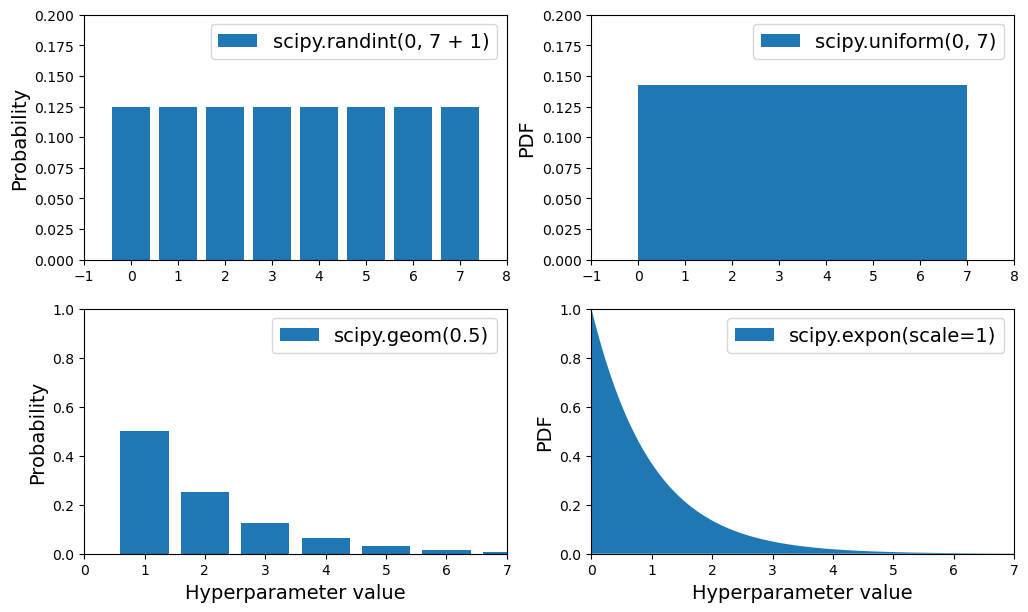

In [121]:
# extra code – plots a few distributions you can use in randomized search
from scipy.stats import randint, uniform, geom, expon

xs1 = np.arange(0, 7 + 1)
randint_distrib = randint(0, 7 + 1).pmf(xs1)

xs2 = np.linspace(0, 7, 500)
uniform_distrib = uniform(0, 7).pdf(xs2)

xs3 = np.arange(0, 7 + 1)
geom_distrib = geom(0.5).pmf(xs3)

xs4 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.bar(xs1, randint_distrib, label="scipy.randint(0, 7 + 1)")
plt.ylabel("Probability")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 2)
plt.fill_between(xs2, uniform_distrib, label="scipy.uniform(0, 7)")
plt.ylabel("PDF")
plt.legend()
plt.axis([-1, 8, 0, 0.2])

plt.subplot(2, 2, 3)
plt.bar(xs3, geom_distrib, label="scipy.geom(0.5)")
plt.xlabel("Hyperparameter value")
plt.ylabel("Probability")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2,2,4)
plt.fill_between(xs4,expon_distrib,label="scipy.expon(scale=1)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.show()

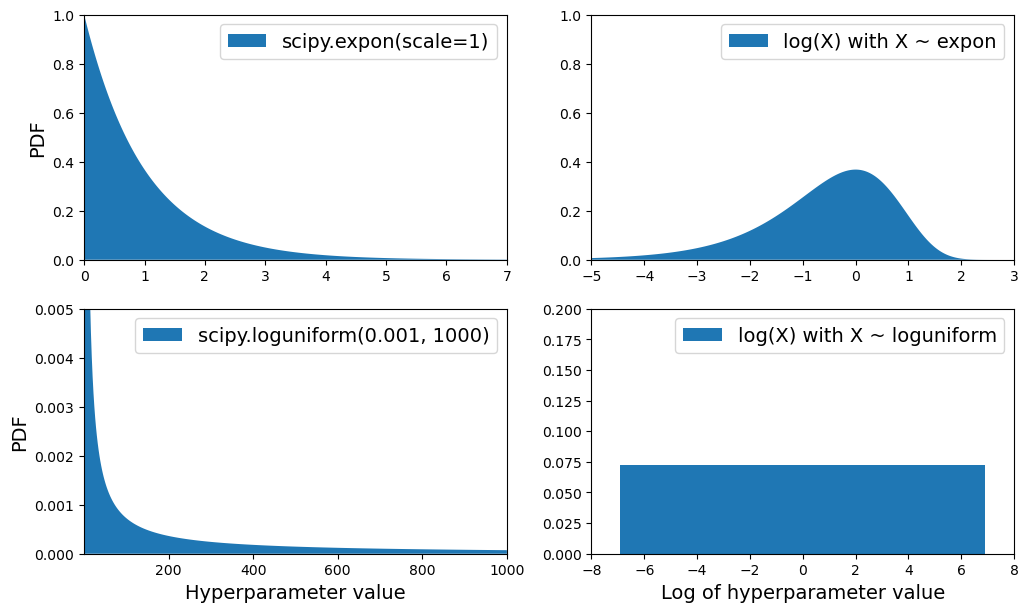

In [122]:
# extra code – shows the difference between expon and loguniform

from scipy.stats import loguniform

xs1 = np.linspace(0, 7, 500)
expon_distrib = expon(scale=1).pdf(xs1)

log_xs2 = np.linspace(-5, 3, 500)
log_expon_distrib = np.exp(log_xs2 - np.exp(log_xs2))

xs3 = np.linspace(0.001, 1000, 500)
loguniform_distrib = loguniform(0.001, 1000).pdf(xs3)

log_xs4 = np.linspace(np.log(0.001), np.log(1000), 500)
log_loguniform_distrib = uniform(loc=np.log(0.001),scale=np.log(1000) - np.log(0.001)).pdf(log_xs4)

plt.figure(figsize=(12, 7))

plt.subplot(2, 2, 1)
plt.fill_between(xs1, expon_distrib,label="scipy.expon(scale=1)")
plt.ylabel("PDF")
plt.legend()
plt.axis([0, 7, 0, 1])

plt.subplot(2, 2, 2)
plt.fill_between(log_xs2, log_expon_distrib,label="log(X) with X ~ expon")
plt.legend()
plt.axis([-5, 3, 0, 1])

plt.subplot(2, 2, 3)
plt.fill_between(xs3, loguniform_distrib,label="scipy.loguniform(0.001, 1000)")
plt.xlabel("Hyperparameter value")
plt.ylabel("PDF")
plt.legend()
plt.axis([0.001, 1000, 0, 0.005])

plt.subplot(2, 2, 4)
plt.fill_between(log_xs4, log_loguniform_distrib,label="log(X) with X ~ loguniform")
plt.xlabel("Log of hyperparameter value")
plt.legend()
plt.axis([-8, 8, 0, 0.2])

plt.show()

Here are the PDF for expon() and loguniform() (left column), as well as the PDF of log(X) (right column). The right column shows the distribution of hyperparameter scales. You can see that expon() favors hyperparameters with roughly the desired scale, with a longer tail towards the smaller scales. But loguniform() does not favor any scale, they are all equally likely.

### Now we use the final model to make predictions and analyze their errors.

In [123]:
final_model = rnd_search.best_estimator_  # includes preprocessing
feature_importances = final_model["random_forest"].feature_importances_
feature_importances.round(2)

array([0.07, 0.05, 0.05, 0.01, 0.01, 0.01, 0.01, 0.19, 0.01, 0.02, 0.01,
       0.01, 0.01, 0.  , 0.01, 0.02, 0.01, 0.02, 0.01, 0.  , 0.01, 0.02,
       0.01, 0.01, 0.01, 0.  , 0.02, 0.01, 0.01, 0.  , 0.01, 0.01, 0.01,
       0.03, 0.01, 0.01, 0.01, 0.01, 0.04, 0.01, 0.02, 0.01, 0.02, 0.01,
       0.02, 0.02, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.01, 0.  , 0.07,
       0.  , 0.  , 0.  , 0.01])

In [124]:
sorted(zip(feature_importances,final_model["preprocessing"].get_feature_names_out()),reverse=True)

[(np.float64(0.18599734460509473), 'log__median_income'),
 (np.float64(0.07338850855844488), 'cat__ocean_proximity_INLAND'),
 (np.float64(0.06556941990883974), 'bedrooms__ratio'),
 (np.float64(0.05364871007672531), 'rooms_per_house__ratio'),
 (np.float64(0.04598870861894748), 'people_per_house__ratio'),
 (np.float64(0.04175269214442518), 'geo__Cluster 30 similarity'),
 (np.float64(0.025976797232869678), 'geo__Cluster 25 similarity'),
 (np.float64(0.023595895886342252), 'geo__Cluster 36 similarity'),
 (np.float64(0.02021056221732893), 'geo__Cluster 9 similarity'),
 (np.float64(0.018606917076661445), 'geo__Cluster 34 similarity'),
 (np.float64(0.01813798837462886), 'geo__Cluster 37 similarity'),
 (np.float64(0.017404353166326745), 'geo__Cluster 18 similarity'),
 (np.float64(0.01677838614384489), 'geo__Cluster 1 similarity'),
 (np.float64(0.015459009666188978), 'geo__Cluster 7 similarity'),
 (np.float64(0.015325731028175922), 'geo__Cluster 32 similarity'),
 (np.float64(0.01507377201503834

In [125]:
X_test = strat_test_set.drop("median_house_value",axis=1)
y_test = strat_test_set["median_house_value"].copy()
final_preds = final_model.predict(X_test)
final_rmse = root_mean_squared_error(final_preds,y_test)
print(final_rmse)

41445.533268606625


Using SciPy's **bootstrap()** function, we calculate a 95% Confidence interval for the test RMSE.

In [127]:
from scipy.stats import bootstrap
def rmse(squared_errors):
    return np.sqrt(np.mean(squared_errors))
confidence = 0.95
squared_errors = (final_preds-y_test)**2
boot_result = bootstrap([squared_errors],rmse,confidence_level=confidence,random_state=42)
rmse_lower, rmse_upper = boot_result.confidence_interval
print(f"95% CI for RMSE: ({rmse_lower:.4f}, {rmse_upper:.4f})")

95% CI for RMSE: (39520.9572, 43701.7681)


Bootstrapping repeatedly samples the squared errors with replacement, calculates RMSE for each resample, and uses those results to estimate uncertainty.

In [128]:
import joblib
joblib.dump(final_model,"my_california_housing_model.pkl")

['my_california_housing_model.pkl']

In [129]:
import joblib

from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics.pairwise import rbf_kernel

def column_ratio(X):
    return X[:, [0]] / X[:, [1]]

def ratio_name(function_transformer, feature_names_in):
    return ["ratio"]

#class ClusterSimilarity(BaseEstimator, TransformerMixin):
#    [...]

final_model_reloaded = joblib.load("my_california_housing_model.pkl")

new_data = housing.iloc[:5]  # pretend these are new districts
predictions = final_model_reloaded.predict(new_data)

We could use pickle instead, but joblib is more efficient.

In [130]:
predictions

array([441046.12, 454713.09, 104832.  , 101316.  , 336181.05])